# **Genetic Algorithm**

Di sini, dilakukan eksperimen algoritma _genetic algorithm_ yang telah diimplementasikan. 

In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src import *

import matplotlib.pyplot as plt

Akan digunakan dataset berikut dengan $3$ truk dan $23$ paket. Fungsi objektif yang digunakan adalah `MaxValueObjective`. 

In [7]:
trucks = [
   Truck("T1", 10, 20, 5, 200),
   Truck("T2", 8, 12, 4, 150),
   Truck("T3", 6, 10, 3, 100),
]

packages = [
   Package("S1", 1, 1, 1, 50, 2, False, 1),
   Package("S2", 1, 2, 1, 45, 3, False, 3),
   Package("S3", 2, 1, 1, 40, 2, True, 2),
   Package("S4", 1, 1, 2, 35, 1, False, 4),
   Package("S5", 2, 2, 1, 55, 4, False, 1),
   
   Package("M1", 3, 4, 2, 80, 10, False, 5),
   Package("M2", 2, 3, 2, 70, 8, True, 2),
   Package("M3", 4, 3, 1, 65, 12, False, 3),
   Package("M4", 3, 3, 3, 90, 15, False, 6),
   Package("M5", 2, 4, 2, 75, 9, False, 1),
   Package("M6", 3, 2, 2, 60, 11, True, 4),
   Package("M7", 4, 2, 3, 85, 14, False, 2),
   
   Package("L1", 5, 6, 3, 120, 25, False, 7),
   Package("L2", 4, 5, 2, 100, 20, False, 3),
   Package("L3", 6, 4, 2, 110, 22, True, 5),
   Package("L4", 5, 5, 3, 130, 30, False, 2),
   Package("L5", 4, 4, 4, 95, 18, False, 4),
   
   Package("H1", 3, 3, 2, 140, 35, False, 1),
   Package("H2", 2, 2, 2, 105, 28, False, 6),
   
   Package("B1", 6, 8, 3, 30, 40, False, 7),
   Package("B2", 5, 7, 4, 25, 35, False, 5),
   
   Package("F1", 2, 3, 1, 115, 6, True, 1),
   Package("F2", 3, 2, 2, 100, 7, True, 1),
]

init_state = State(packages, trucks, init="random_feasible")
draw_state(init_state)

objective = MaxValueObjective()

## **Variasi Population Size**

Di sini, akan dilakukan eksperimen variasi `population_size` dengan `max_generations=500` tetap.

In [26]:
results_1 = []

for population_size in [4,8,15]:
   solver_1 = GeneticAlgorithm(objective, population_size=population_size, max_generations=500)
   results_1.append(solver_1.solve(init_state))

Berikut hasil penyelesaiannya serta visualisasinya. 

In [27]:
for result in results_1:
   print(result)
   draw_state(result.final_state)

Solver: GeneticAlgorithm
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 1.436s
Total Iterations: 500
Initial Objective: 845.00
Final Objective: 1630.00
----------------------------------------------------------------------------------------------------
Population Size      : 4
Max Generations      : 500
Max History          : [501 values]
Average History      : [501 values]
Final Objective Value : 1630


Solver: GeneticAlgorithm
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 2.656s
Total Iterations: 500
Initial Objective: 965.00
Final Objective: 1680.00
----------------------------------------------------------------------------------------------------
Population Size      : 8
Max Generations      : 500
Max History          : [501 values]
Average History      : [501 values]
Final Objective Value : 1680


Solver: GeneticAlgorithm
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 4.862s
Total Iterations: 500
Initial Objective: 1030.00
Final Objective: 1720.00
----------------------------------------------------------------------------------------------------
Population Size      : 15
Max Generations      : 500
Max History          : [501 values]
Average History      : [501 values]
Final Objective Value : 1720


Berikut sejarah nilai objektif pada eksperimen. 

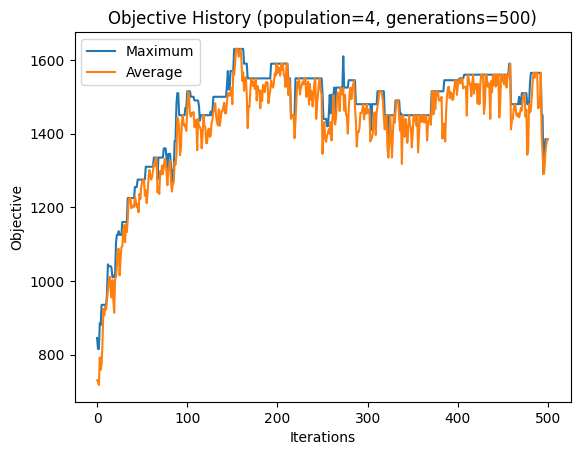

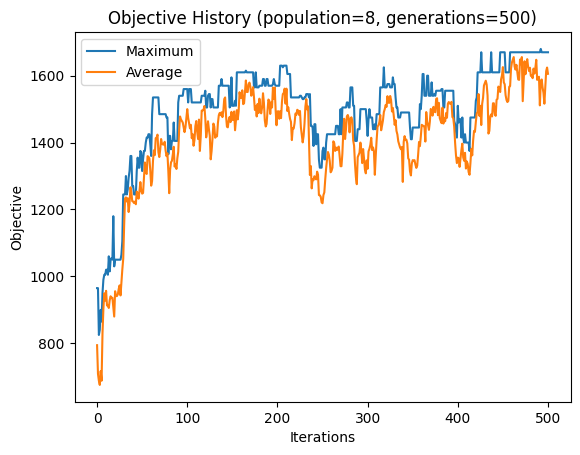

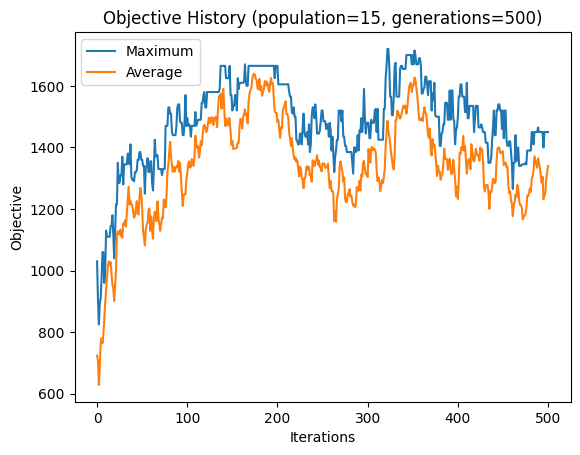

In [28]:
for result in results_1:
   plt.plot(result.metadata["max_history"], label="Maximum")
   plt.plot(result.metadata["average_history"], label="Average")
   plt.title(f"Objective History (population={result.metadata['population_size']}, generations={result.metadata['max_generations']})")
   plt.xlabel("Iterations")
   plt.ylabel("Objective")
   plt.legend()
   plt.show()

## **Variasi Maximum Generations**

Di sini, akan dilakukan eksperimen variasi `max_generations` dengan `population_size=6` tetap.

In [23]:
results_2 = []

for max_generations in [50, 500, 1000]:
   solver_2 = GeneticAlgorithm(objective, population_size=6, max_generations=max_generations)
   results_2.append(solver_2.solve(init_state))

Berikut hasil penyelesaiannya serta visualisasinya. 

In [24]:
for result in results_2:
   print(result)
   draw_state(result.final_state)

Solver: GeneticAlgorithm
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 0.120s
Total Iterations: 50
Initial Objective: 1010.00
Final Objective: 1230.00
----------------------------------------------------------------------------------------------------
Population Size      : 6
Max Generations      : 50
Max History          : [51 values]
Average History      : [51 values]
Final Objective Value : 1230


Solver: GeneticAlgorithm
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 1.827s
Total Iterations: 500
Initial Objective: 1110.00
Final Objective: 1665.00
----------------------------------------------------------------------------------------------------
Population Size      : 6
Max Generations      : 500
Max History          : [501 values]
Average History      : [501 values]
Final Objective Value : 1665


Solver: GeneticAlgorithm
Objective Function: MaxValueObjective
----------------------------------------------------------------------------------------------------
Runtime: 4.142s
Total Iterations: 1,000
Initial Objective: 1030.00
Final Objective: 1700.00
----------------------------------------------------------------------------------------------------
Population Size      : 6
Max Generations      : 1000
Max History          : [1001 values]
Average History      : [1001 values]
Final Objective Value : 1700


Berikut sejarah nilai objektif pada eksperimen. 

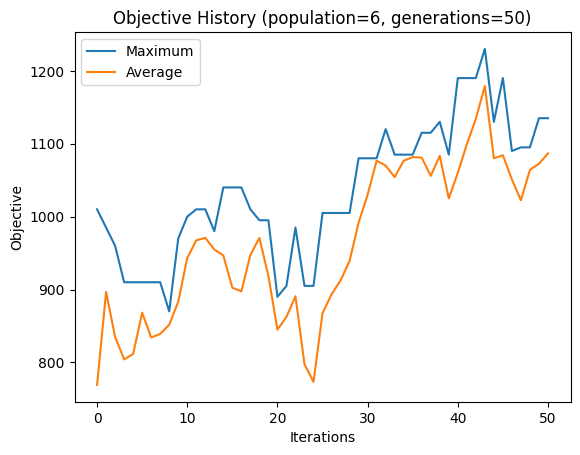

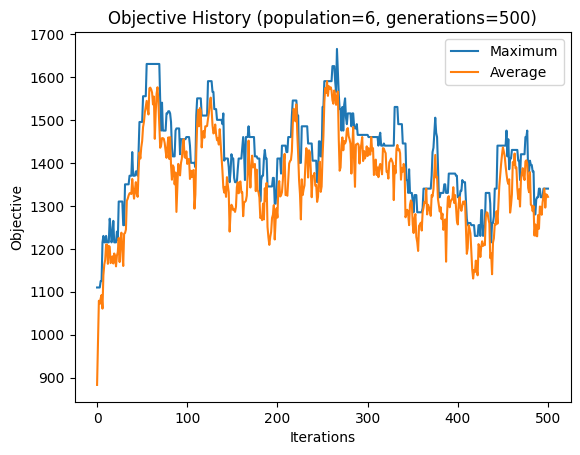

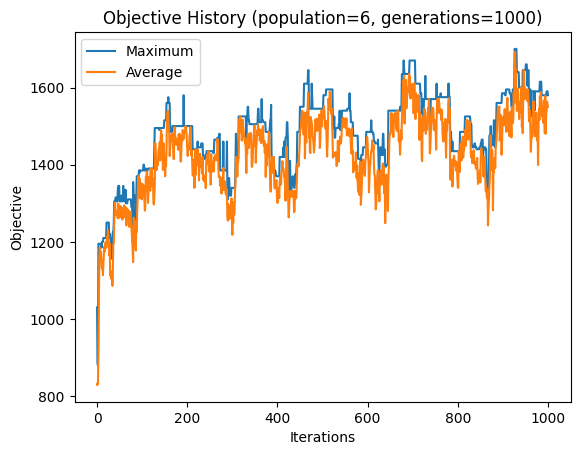

In [25]:
for result in results_2:
   plt.plot(result.metadata["max_history"], label="Maximum")
   plt.plot(result.metadata["average_history"], label="Average")
   plt.title(f"Objective History (population={result.metadata['population_size']}, generations={result.metadata['max_generations']})")
   plt.xlabel("Iterations")
   plt.ylabel("Objective")
   plt.legend()
   plt.show()